# **Лабораторна робота 1**
**Розгортання інфраструктури розробки: Miniconda, VS Code, Git/GitHub та базові режими виконання Python**

**Мета:** Опанувати повний цикл розгортання та конфігурації професійного інженерного середовища для розробки програмного забезпечення мовою Python. Набути практичних навичок створення та ізоляції віртуальних середовищ за допомогою пакетного менеджера Miniconda, інтеграції середовища розробки Visual Studio Code із підсистемою налагодження debugpy та мовним сервером Pylance, налаштування розподіленої системи контролю версій Git та віддаленого репозиторію GitHub. Дослідити фундаментальні відмінності виконання програмного коду в інтерактивній консолі REPL, термінальному пакетному режимі та інтерактивному блокноті Jupyter Notebook.


**Зроблено:** П'ятибрат Дмитро

**Варіант:** 16

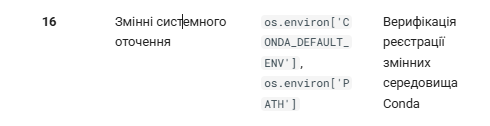
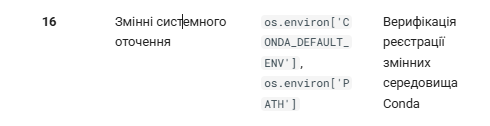

In [2]:
import os
import sys

def verify_conda_environment():
    #Перевірка назви активного середовища
    conda_env = os.environ.get('CONDA_DEFAULT_ENV')
    conda_prefix = os.environ.get('CONDA_PREFIX')
    path = os.environ.get('PATH', '')

    print("Результати верифікації Conda:")

    # Верифікація CONDA_DEFAULT_ENV
    if conda_env:
        print(f"Активне середовище (CONDA_DEFAULT_ENV): {conda_env}")
    else:
        print("Попередження: CONDA_DEFAULT_ENV не зареєстровано (середовище не активовано).")

    # Верифікація CONDA_PREFIX
    if conda_prefix:
        print(f"Шлях до середовища (CONDA_PREFIX): {conda_prefix}")
    else:
        print("Попередження: CONDA_PREFIX не знайдено.")

    # Верифікація PATH
    print("\nПеревірка PATH:")
    if conda_prefix and conda_prefix in path:
        print("Успішно: Шлях до Conda знайдено у змінній PATH.")
    else:
        print("Увага: Шлях активного середовища Conda відсутній на початку PATH.")

    # Звірка з поточним інтерпретатором Python
    print("\nПоточний інтерпретатор:")
    print(f"sys.executable: {sys.executable}")
    if conda_prefix and sys.executable.startswith(conda_prefix):
        print("Успішно: Скрипт виконується саме інтерпретатором Conda.")
    else:
        print("Увага: Python запущено не з активного середовища Conda.")

if __name__ == '__main__':
    verify_conda_environment()

Результати верифікації Conda:
Активне середовище (CONDA_DEFAULT_ENV): py_base
Шлях до середовища (CONDA_PREFIX): C:\Users\stati\.conda\envs\py_base

Перевірка PATH:
Успішно: Шлях до Conda знайдено у змінній PATH.

Поточний інтерпретатор:
sys.executable: C:\Users\stati\.conda\envs\py_base\python.exe
Успішно: Скрипт виконується саме інтерпретатором Conda.


**Контрольні запитання**


1. venv ізолює лише Python-пакети та покладається на системні динамічні С-бібліотеки ОС (glibc, CUDA, OpenBLAS). Miniconda керує власним бінарним середовищем, ізолюючи не лише Python, а й низькорівневі C/C++/Fortran-бібліотеки, компілятори та системні залежності.

2. У мові C int — це 4 байти чистого машинного значення в пам'яті або стек-фреймі. У CPython будь-яке число — це об'єкт PyLongObject на купі (heap). У 64-бітній системі він містить заголовок PyVarObject: лічильник посилань ob_refcnt (8 байтів), вказівник на тип ob_type (8 байтів), розмір числа ob_size (8 байтів) та масив цифр ob_digit (для нуля виділяється мінімальний 4-байтний елемент). Разом: 8 + 8 + 8 + 4 = 28 байтів.

3. Призначення: оптимізація виділення пам'яті та підвищення швидкодії шляхом повторного використання об'єктів для діапазону від -5 до 256 замість створення нових через malloc. Межі обрані емпірично, оскільки ці числа зустрічаються найчастіше (індекси, лічильники циклів, коди повернення); необмежене кешування призвело б до неконтрольованого перевитрачання пам'яті.

4. Working Tree містить реальні файли на диску; Staging Area (Index) фіксує підготовлений знімок змін у двійковому файлі індексу; Local Repository зберігає стиснуті об'єкти (blobs, trees, commits) у .git/objects. Цілісність орієнтованого ациклічного графа (DAG) гарантує криптографічне гешування (SHA-1 або SHA-256): кожен коміт містить геш батьківського вузла, тому будь-яка зміна історії змінює всі наступні геші.

5. REPL компілює і виконує кожен вираз покроково у пам'яті одного сеансу безпосередньо в терміналі. Запуск скрипта ініціалізує новий ізольований процес Python, послідовно виконує весь код від початку до кінця і повністю звільняє пам'ять при завершенні. Jupyter працює через архітектуру «клієнт–сервер» (вебінтерфейс через ZeroMQ звертається до ядра IPython), дозволяючи зберігати спільний стан пам'яті та виконувати фрагменти коду в довільному порядку.

Файл launch.json зберігає конфігурацію запуску (шлях до інтерпретатора, аргументи, змінні середовища, мережеві порти для attach/launch). Бібліотека debugpy реалізує протокол Debug Adapter Protocol (DAP): вона підключається до процесу Python через хуки інтерпретатора (sys.settrace), перехоплює виконання на точках зупинки та транслює команди керування (крок уперед, інспекція змінних) між IDE та процесом.